# TDC V18: 25 MHz finite-burst qualification

Requires VERSION18 / ID0x54444312, minimum40 ns,250 MHz sampling and512 taps.
Power-up/reset input is SINGLE (DIO2_P/E1 pin7); LVDS remains selectable.
V17's capture/encoder/LUT arithmetic is retained. V18 targets pulse-launch
routing, terminal comparisons and control fanout. No new timing closure or
hardware precision is established until the external build and this run finish.

V17 demonstrated16384 calibrated pulses at25 MHz after retries, but retained
large width bias and mean shifts between starts. The accepted full burst had
305 ps SD and+2.45 ns bias. Treat V18 as a targeted timing repair, not a cure
for those errors. Independent AWG/frame clocks still need alignment checks.

Build externally, enter the exact bitstream identity and new routed WNS, then
restart the kernel and run from the top. Collect fresh RISE/FALL calibration
for V18; V17 LUTs must not be assumed valid for this new implementation.

Default retention is complete_only: full CSV/raw diagnostics are saved only
for successful fully complete captures. Incomplete/error/DC attempts retain
compact settings, flags/counts, errors and retry bookkeeping. Yield statistics
include every attempt. Set CAPTURE_RETENTION="all" explicitly for raw debugging,
or "nonzero" to retain partially complete captures too. Nothing deletes older
successful measurements automatically.

Matched source/frame periods, source identity, LUT qualification, integrity,
fine validity and fresh alignment gates remain enabled. Offset candidates
require fresh validation; the frame sweep runs before the alignment gate.


## 1. Configuration

Use the envscpi kernel. Calibration initially uses the established1 MHz settings;
fresh25 MHz captures then test transfer to the higher operating rate.


In [1]:
# If needed, uncomment and run in this notebook's kernel, then restart it:
# %pip install numpy matplotlib pyvisa
# PyVISA also needs the vendor VISA runtime with USB support (already used by discovery).

RP_IP = "169.254.77.151"
SCPI_PORT = 5000
VISA_RESOURCE = "USB0::0x1AB1::0x0647::DG5R270700006::INSTR"
VISA_BACKEND = ""           # Default installed vendor VISA runtime.
AWG_COMMAND_DELAY_S = 0.02  # Space USB commands, including error-queue queries.
AWG_CHANNEL = 1
AWG_SERIAL = "DG5R270700006"
LOW_V, HIGH_V = 0.0, 3.3
EXPECTED_WIDTH_VERSION = 18
BITSTREAM_LABEL = "v18: enter exact routed bitstream identity"
IMPLEMENTATION_WNS_NS = None  # Enter the NEW V18 routed WNS.

FRAME_COUNT = 8192           # One nominal source cycle per acquisition frame.
SWEEP_FRAMES = 4096
HOST_TIMEOUT_S = 30.0
BASELINE_FREQUENCY_HZ = 25_000_000.0
BASELINE_WIDTH_NS = 20.2
CAL_FREQUENCIES_HZ = [997_003.0, 991_027.0, 983_039.0]  # Both instruments follow each common rate.
CAL_ROUNDS = 8               # 24 bursts; usable count depends on alignment.
MIN_EDGE_SAMPLES = 50_000
MIN_POPULATED_BINS = 32
KNOWN_DEAD_ZONES = []        # Physically characterized dead bins; keep unresolved gaps separate.
# Recharacterize the NEW build first. Old v9 exceptions were FALL 91-93 / 99-101.
PROVISIONAL_MISSING_CODE_RANGES = {}
REFERENCE_OVERRIDES_NS = {}  # Example: {500.25: 500.18}; use measured widths, in ns.
RESULTS_PARENT = "tdc_rigol_results"
ALIGNMENT_SURVEY_REPEATS = 4
ALIGNMENT_SURVEY_FRAMES = 1024
MEASURED_RETURN_DELAY_NS = None  # Independent scope observation; does not auto-set offset.
FRAME_OFFSET_NS = 0              # V14+: shift frame boundary; choose from scope phase measurement.
FRAME_OFFSETS_BY_PERIOD_NS = {}   # Optional {common_period_ns: offset_ns}, overrides global setting.
# Offset is a multiple of 4 ns, 0..262140 ns, strictly less than each common period.
# Example ONLY: for T=1004, input rise=800/fall=1500 ns, offset=600 ns encloses the pulse.
# This helper restarts sources each capture. Unlocked AWG phase is not made repeatable by OFFSET.
TARGET_COMPLETE_FRACTION = 1.0   # Require every requested pulse in the selected burst.
PHASE_RETRIES = True            # Restart incomplete pulse bursts, including 0 complete.
PHASE_RETRY_MAX_ATTEMPTS = 50    # Per test; prevents an endless loop with absent/bad input.
PHASE_RETRY_DELAY_S = 0.2        # Delay after failed attempt; settings stay unchanged.
DRIFT_REPEATS = 3

# Diagnose high-rate frame placement before the alignment gate.
RUN_FRAME_OFFSET_SWEEP = True
OFFSET_SWEEP_POINTS = [(15e6, 32.2), (20e6, 24.2), (25e6, 20.2)]
OFFSET_SWEEP_FRAMES = 512
OFFSET_SWEEP_REPEATS = 2

CAPTURE_RETENTION = "complete_only"  # all / nonzero / complete_only


In [2]:
import json
import sys
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Works when Jupyter starts either in the repository root or in scpi-tests.
candidates = [Path.cwd(), Path.cwd()/"scpi-tests"]
helper_dir = next((p for p in candidates if (p/"tdc_rigol_tools.py").is_file()), None)
if helper_dir is None:
    raise RuntimeError("Start Jupyter in RedPitaya_app or scpi-tests; keep tdc_rigol_tools.py beside this notebook")
sys.path.insert(0, str(helper_dir.resolve()))
# Reload edited helper code when rerunning this cell in an existing kernel.
import importlib
import tdc_rigol_tools
importlib.reload(tdc_rigol_tools)
from tdc_rigol_tools import (Bench, save_json, summarize, rows, quality_guard,
                            build_candidate, plot_capture, plot_candidate, plot_sweep,
                            precision_comparison, fit_width_reference,
                            validate_width_reference, phase_residuals, signal_identity_check,
                            plan_matched_period, alignment_survey, input_path_diagnostic, gpio_pulse_diagnostic, frame_offset_survey)

# Use the configuration cell as the single source of the expected version.
if EXPECTED_WIDTH_VERSION != 18:
    raise ValueError("Configure expected VERSION18 for this notebook, then rerun setup")
FRAME_OFFSET_NS = globals().get("FRAME_OFFSET_NS", 0)
FRAME_OFFSETS_BY_PERIOD_NS = globals().get("FRAME_OFFSETS_BY_PERIOD_NS", {})
PHASE_RETRIES = globals().get("PHASE_RETRIES", True)
PHASE_RETRY_MAX_ATTEMPTS = globals().get("PHASE_RETRY_MAX_ATTEMPTS", 50)
PHASE_RETRY_DELAY_S = globals().get("PHASE_RETRY_DELAY_S", 0.2)
config = dict(expected_width_version=EXPECTED_WIDTH_VERSION, rp_ip=RP_IP, scpi_port=SCPI_PORT, visa_resource=VISA_RESOURCE,
              visa_backend=VISA_BACKEND, awg_channel=AWG_CHANNEL, awg_serial=AWG_SERIAL,
              low_v=LOW_V, high_v=HIGH_V, bitstream_label=BITSTREAM_LABEL,
              implementation_wns_ns=IMPLEMENTATION_WNS_NS, frame_count=FRAME_COUNT, capture_retention=CAPTURE_RETENTION,
              host_timeout_s=HOST_TIMEOUT_S, socket_timeout_s=10.0,
              visa_timeout_ms=10000, awg_command_delay_s=AWG_COMMAND_DELAY_S, settle_s=0.05, timing_policy="matched_period_v1",
              measured_return_delay_ns=MEASURED_RETURN_DELAY_NS,
              frame_offset_ns=FRAME_OFFSET_NS, frame_offsets_by_period_ns=FRAME_OFFSETS_BY_PERIOD_NS,
              phase_retries=PHASE_RETRIES, phase_retry_max_attempts=PHASE_RETRY_MAX_ATTEMPTS,
              phase_retry_delay_s=PHASE_RETRY_DELAY_S)
from local_data import results_directory
RUN_DIR = results_directory(RESULTS_PARENT)/datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
bench = Bench(config, RUN_DIR)
save_json(RUN_DIR/"test_plan.json", dict(cal_frequencies_hz=CAL_FREQUENCIES_HZ,
          cal_rounds=CAL_ROUNDS, min_edge_samples=MIN_EDGE_SAMPLES,
          min_populated_bins=MIN_POPULATED_BINS, known_dead_zones=KNOWN_DEAD_ZONES,
          provisional_missing_code_ranges=PROVISIONAL_MISSING_CODE_RANGES,
          reference_overrides_ns=REFERENCE_OVERRIDES_NS, timing_policy="matched_period_v1",
          target_complete_fraction=TARGET_COMPLETE_FRACTION,
          measured_return_delay_ns=MEASURED_RETURN_DELAY_NS))

def reference_for(width):
    return REFERENCE_OVERRIDES_NS.get(float(width))

def take(label, frequency, width, *, fine=False, frames=SWEEP_FRAMES):
    capture = bench.acquire(label, frequency, float(width), frames=frames, fine=fine,
                            reference_ns=reference_for(width))
    settings, timing, summary = capture["awg"], capture["timing"], capture["summary"]
    print(f"Requested common rate {frequency:g} Hz; applied AWG/frame "
          f"{timing['common_frequency_hz']:.9g} Hz / {timing['common_period_ns']} ns")
    print(f"Readbacks: AWG period {settings['period_ns']:.9g} ns, "
          f"FPGA period {timing['fpga_period_readback_ns']} ns; "
          f"AWG HIGH {settings['width_ns']:.9g} ns (requested {width:g})")
    print(f"{label}: {summary['complete_pulses']}/{summary['total_frames']} complete "
          f"({summary['complete_fraction']:.1%}); operating target 100% after alignment; "
          f"phase lock unverified; RISE/FALL {summary['fine_edge_quality']}; "
          f"FPGA-fine calibrated {summary['calibrated_pulses']}")
    retry = capture.get("phase_retry")
    if retry:
        print(f"Selected source start {retry['attempt']}/{retry['max_attempts']}; "
              f"complete fraction across all starts: {retry['complete_fraction_all_attempts']:.1%}; "
              f"ledger: {retry['ledger_path']}")
    if "edge_diagnostics" in capture:
        d = capture["edge_diagnostics"]
        print("Sparse edge pairs:", d["valid_pairs"], "/", d["sampled"],
              "; RISE/FALL drift span (ns):",
              d["rise_drift"]["range_ns"], d["fall_drift"]["range_ns"])
    return capture


def show_and_save(fig, name):
    fig.savefig(RUN_DIR/name, dpi=160, bbox_inches="tight")
    display(fig)
    plt.close(fig)

print("Notebook requires TDC VERSION:", EXPECTED_WIDTH_VERSION)
print("Helper loaded from:", Path(tdc_rigol_tools.__file__).resolve())
print("Python:", sys.executable)
print("Results:", RUN_DIR.resolve())
if IMPLEMENTATION_WNS_NS is None or IMPLEMENTATION_WNS_NS < 0:
    print("PROVISIONAL: implementation timing is unknown or failed; calibration cannot repair this.")
BASELINE_PLAN = plan_matched_period(BASELINE_FREQUENCY_HZ, 40)
print("Common baseline timing:", BASELINE_PLAN)
print("Equal programmed periods; phase lock and return-delay calibration remain unverified.")
print("Incomplete pulse-burst restarts:", PHASE_RETRIES, "; maximum starts per test:", PHASE_RETRY_MAX_ATTEMPTS)


Notebook requires TDC VERSION: 18
Helper loaded from: C:\Users\kairan\vscodeprj\RedPitaya_app\scpi-tests\tdc_rigol_tools.py
Python: c:\Users\kairan\miniconda3\envs\envscpi\python.exe
Results: C:\Users\kairan\RedPitaya_local_data\RedPitaya_app\scpi-tests\tdc_rigol_results\20261026T150410_720673Z
PROVISIONAL: implementation timing is unknown or failed; calibration cannot repair this.
Common baseline timing: {'policy': 'matched_period_v1', 'requested_frequency_hz': 25000000.0, 'requested_period_ns': 40.0, 'common_period_ns': 40, 'common_frequency_hz': 25000000.0, 'grid_ns': 4, 'period_rounding_ns': 0.0, 'phase_lock_verified': False, 'note': 'Both instruments receive the same nominal period. Relative phase, clock drift and launch-to-return delay are not established by equal settings.'}
Equal programmed periods; phase lock and return-delay calibration remain unverified.
Incomplete pulse-burst restarts: True ; maximum starts per test: 50


In [3]:
PREFLIGHT = bench.preflight()
MINIMUM_PERIOD_NS = PREFLIGHT["image"]["minimum_period_ns"]
print(json.dumps(PREFLIGHT, indent=2))
if MINIMUM_PERIOD_NS != 40:
    raise RuntimeError("This25 MHz qualification requires a40 ns minimum frame period")


{
  "image": {
    "width_version": 18,
    "tick_ps": 4000,
    "taps": 512,
    "capacity": 16384,
    "bitstream_label": "v18: enter exact routed bitstream identity",
    "implementation_wns_ns": null,
    "association_policy": "shifted_single_frame_v14",
    "minimum_period_ns": 40,
    "diagnostic_stride": 64,
    "diagnostic_capacity": 256
  },
  "input_before_setup": "SINGLE",
  "selected_input": "SINGLE",
  "awg_identity": "RIGOL TECHNOLOGIES,DG5502 Pro,DG5R270700006,00.01.00",
  "original_awg_settings": "\"PULS,+2.500000000000000E+07,+3.300000000000000E+00,+1.650000000000000E+00,+0.000000000000000E+00\"",
  "original_clock_source": "INT"
}


## Input-path diagnostic: run this before alignment

One attempt per setting, with every frame saved and no phase retries or LUT.
DC LOW/HIGH/LOW must read 0/1/0 on DIO2_P. WIDTH should mark HIGH_START
throughout DC HIGH and no complete pulses for DC. GPIO passing while WIDTH
fails isolates the mux/sampler/image side. Both failing points to the source,
physical connection or pin path. The rate ladder includes 20.2 ns pulses at
both 1 and 25 MHz to distinguish pulse width from repetition rate.
Actual rates use the common 4 ns period grid and are printed/saved.

Run through the diagnostic cell first and inspect input_path_diagnostic.json.
The alignment cell stops if a setting sees no rising/falling edges. Partial
yield is retained and investigated by alignment; it does not fail this input
presence check. Every acquisition stops both outputs, including on errors.


In [4]:
INPUT_DIAGNOSTIC, input_diagnostic_captures = input_path_diagnostic(bench, frames=512)
print(json.dumps(INPUT_DIAGNOSTIC, indent=2))


input_dc_low_before GPIO: {'pin': 'DIO2_P', 'samples': [0, 0, 0, 0, 0, 0, 0, 0], 'expected_level': 0, 'matched': True} flags: {'NO_RISE': 512, 'NO_FALL': 512}
input_dc_high GPIO: {'pin': 'DIO2_P', 'samples': [1, 1, 1, 1, 1, 1, 1, 1], 'expected_level': 1, 'matched': True} flags: {'NO_RISE': 512, 'NO_FALL': 512, 'HIGH_START': 512, 'SATURATED': 512}
input_dc_low_after GPIO: {'pin': 'DIO2_P', 'samples': [0, 0, 0, 0, 0, 0, 0, 0], 'expected_level': 0, 'matched': True} flags: {'NO_RISE': 512, 'NO_FALL': 512}
Input rate diagnostic: {'frequency_hz': 1000000.0, 'period_ns': 1000, 'width_ns': 500.2, 'complete': 512, 'frames': 512, 'frames_with_rise': 512, 'frames_with_fall': 512, 'flag_counts': {'VALID': 512, 'COARSE_ONLY': 512}, 'capture_files': {'csv': 'C:\\Users\\kairan\\RedPitaya_local_data\\RedPitaya_app\\scpi-tests\\tdc_rigol_results\\20261026T150410_720673Z\\0004_input_rate_00_1e+06_w500.csv', 'json': 'C:\\Users\\kairan\\RedPitaya_local_data\\RedPitaya_app\\scpi-tests\\tdc_rigol_results\\2

### GPIO pulse check with WIDTH idle and launch OFF/ON

V17's earlier source-state anomaly cleared after an AWG restart. This optional
follow-up runs if the new input diagnostic loses pulse edges. It checks four
AWG widths at1 MHz with launch OFF/ON while WIDTH stays idle. GPIO polling
can alias and cannot independently measure pulse width or frequency.
Inspect the saved snapshot fractions and active AWG width/duty readbacks.


In [5]:
if not globals().get("INPUT_DIAGNOSTIC", {}).get("ready_for_alignment", False):
    GPIO_DIAGNOSTIC = gpio_pulse_diagnostic(bench, samples=128)
    print("GPIO-only results saved:", RUN_DIR/"gpio_pulse_diagnostic.json")
    for point in GPIO_DIAGNOSTIC["points"]:
        print({key: point[key] for key in ("requested_width_ns", "launch_enabled", "high_fraction", "nominal_high_fraction")},
              "active AWG duty:", point["active_awg"]["duty_query_percent"],
              "width/duty consistent:", point["active_awg"]["width_duty_consistent"])
else:
    print("Input-path presence checks passed; GPIO follow-up not needed.")


GPIO only: AWG HIGH 20.2 ns/1000 ns; launch OFF; 3/128 HIGH snapshots; nominal duty 2.0%
GPIO only: AWG HIGH 20.2 ns/1000 ns; launch ON; 4/128 HIGH snapshots; nominal duty 2.0%
GPIO only: AWG HIGH 100.2 ns/1000 ns; launch OFF; 14/128 HIGH snapshots; nominal duty 10.0%
GPIO only: AWG HIGH 100.2 ns/1000 ns; launch ON; 12/128 HIGH snapshots; nominal duty 10.0%
GPIO only: AWG HIGH 500.2 ns/1000 ns; launch OFF; 66/128 HIGH snapshots; nominal duty 50.0%
GPIO only: AWG HIGH 500.2 ns/1000 ns; launch ON; 62/128 HIGH snapshots; nominal duty 50.0%
GPIO only: AWG HIGH 800.2 ns/1000 ns; launch OFF; 108/128 HIGH snapshots; nominal duty 80.0%
GPIO only: AWG HIGH 800.2 ns/1000 ns; launch ON; 103/128 HIGH snapshots; nominal duty 80.0%
GPIO-only results saved: C:\Users\kairan\RedPitaya_local_data\RedPitaya_app\scpi-tests\tdc_rigol_results\20261026T150410_720673Z\gpio_pulse_diagnostic.json
{'requested_width_ns': 20.2, 'launch_enabled': False, 'high_fraction': 0.0234375, 'nominal_high_fraction': 0.0202} a

## Frame-offset sweep — available before the alignment gate

This section runs even when high-rate input presence failed. Preflight and DC
LOW/HIGH/LOW checks must pass first. It tests every legal4 ns offset:0..64 ns
at the actual14.705882 MHz rate,0..48 ns at19.230769 MHz, and0..36 ns at25 MHz.
AWG and FPGA keep matched periods68/52/40 ns; no frequency detuning is used.

Defaults:512 frames per offset, two complete passes,80 captures total. Allow
several minutes. Every capture is coarse-only, with no phase retries. Partial,
missing-edge and boundary records are saved; all outputs stop after each capture.
An integrity/communication/cleanup error stops the sweep and preserves progress.

Each acquisition restarts the independent sources, so startup phase and drift
can change as well as the offset. This is a screening survey, not a controlled
phase scan or proof of phase lock. Candidates require a fully complete burst
on every repeat; no selection uses width error, SD or fine validity. Fresh
alignment captures below must pass before the calibration cells can run.

The original notebook outputs are backed up under
build/tdc-25mhz-review/frame-offset-sweep-review/before_offset_sweep.ipynb.


In [6]:
if not (globals().get("INPUT_DIAGNOSTIC", {}).get("gpio_dc_pass", False)
        and INPUT_DIAGNOSTIC.get("width_dc_pass", False)):
    raise RuntimeError("Run preflight/input diagnostic and resolve DC LOW/HIGH tracking first")
OFFSET_SWEEP = None
if RUN_FRAME_OFFSET_SWEEP:
    OFFSET_SWEEP = frame_offset_survey(bench, points=OFFSET_SWEEP_POINTS,
                                      frames=OFFSET_SWEEP_FRAMES, repeats=OFFSET_SWEEP_REPEATS)
    print("All attempts saved:", OFFSET_SWEEP["ledger_path"])
    for period in sorted({p["period_ns"] for p in OFFSET_SWEEP["offset_summary"]}, reverse=True):
        print(f"Period {period} ns: offset / complete starts / total starts / all-frame completeness")
        for point in OFFSET_SWEEP["offset_summary"]:
            if point["period_ns"] == period:
                print(point["offset_ns"], point["complete_starts"], point["starts"],
                      f"{point['complete_fraction_all_frames']:.1%}")
    print("Candidate offsets by period (ns):", OFFSET_SWEEP["suggested_offsets_by_period_ns"])
else:
    print("Sweep skipped; configured offsets still require fresh alignment validation.")


Offset scan 1/80: 14.7059 MHz, offset 0 ns: 0/512; {'NO_FALL': 512, 'HIGH_START': 512, 'EXTRA_EDGES': 512, 'SATURATED': 512}
Offset scan 2/80: 14.7059 MHz, offset 4 ns: 0/512; {'NO_FALL': 512, 'HIGH_START': 512, 'EXTRA_EDGES': 512, 'SATURATED': 512}
Offset scan 3/80: 14.7059 MHz, offset 8 ns: 0/512; {'HIGH_START': 2, 'BOUNDARY': 512}
Offset scan 4/80: 14.7059 MHz, offset 12 ns: 512/512; {'VALID': 512, 'COARSE_ONLY': 512}
Offset scan 5/80: 14.7059 MHz, offset 16 ns: 0/512; {'NO_FALL': 512, 'HIGH_START': 512, 'EXTRA_EDGES': 512, 'SATURATED': 512}
Offset scan 6/80: 14.7059 MHz, offset 20 ns: 512/512; {'VALID': 512, 'COARSE_ONLY': 512}
Offset scan 7/80: 14.7059 MHz, offset 24 ns: 512/512; {'VALID': 512, 'COARSE_ONLY': 512}
Offset scan 8/80: 14.7059 MHz, offset 28 ns: 0/512; {'NO_FALL': 512, 'HIGH_START': 512, 'EXTRA_EDGES': 512, 'SATURATED': 512}
Offset scan 9/80: 14.7059 MHz, offset 32 ns: 0/512; {'NO_FALL': 512, 'HIGH_START': 512, 'EXTRA_EDGES': 512, 'SATURATED': 512}
Offset scan 10/80: 

### Apply candidates, then validate fresh25 MHz bursts

The next cell applies the first offset passing every sweep repeat for each
period. Edit MANUAL_OFFSET_OVERRIDES_NS to choose another legal offset from
the saved table. Mapping keys are frame periods in ns, not frequencies.
For example,{40:12} means a12 ns offset for25 MHz; it is not a known good value.
Periods with no candidate retain the previous configuration and may still fail.

The alignment gate now checks DC health and fresh complete25 MHz bursts with
these offsets. A failed unswept14.7 MHz point no longer prevents this fresh
25 MHz check. No old diagnostic result is marked passed or overwritten.
If no offset repeatedly succeeds, keep the failure evidence for HDL/timing and
source-phase investigation; do not bypass the fresh validation gate.


In [7]:
MANUAL_OFFSET_OVERRIDES_NS = {}  # Optional, e.g. {40:12}; choose from your sweep.
APPLIED_OFFSETS = {int(k): v for k,v in bench.config.get("frame_offsets_by_period_ns", {}).items()}
if OFFSET_SWEEP is not None:
    APPLIED_OFFSETS.update({int(k): int(v) for k,v in
                            OFFSET_SWEEP["suggested_offsets_by_period_ns"].items()})
APPLIED_OFFSETS.update(MANUAL_OFFSET_OVERRIDES_NS)
# Canonicalize keys so stale string/int versions of one period cannot conflict.
APPLIED_OFFSETS = {int(k): v for k,v in APPLIED_OFFSETS.items()}
for period, offset in APPLIED_OFFSETS.items():
    if isinstance(offset,bool) or not isinstance(offset,int) or offset % 4 or not 0 <= offset < period:
        raise ValueError(f"Offset {offset!r} must be a4 ns multiple inside period {period} ns")
FRAME_OFFSETS_BY_PERIOD_NS = APPLIED_OFFSETS
bench.config["frame_offsets_by_period_ns"] = dict(APPLIED_OFFSETS)
save_json(RUN_DIR/"applied_frame_offsets.json", dict(offsets_by_period_ns=APPLIED_OFFSETS,
          sweep_ledger=None if OFFSET_SWEEP is None else OFFSET_SWEEP["ledger_path"],
          qualification="Candidates only; fresh alignment still required"))
print("Applied offsets by frame period (ns):", APPLIED_OFFSETS)


Applied offsets by frame period (ns): {68: 12, 52: 0}


In [8]:
if not (globals().get("INPUT_DIAGNOSTIC", {}).get("gpio_dc_pass", False)
        and INPUT_DIAGNOSTIC.get("width_dc_pass", False)):
    raise RuntimeError("Resolve DC input tracking before alignment")
ALIGNMENT_SURVEY, alignment_captures = alignment_survey(
    bench, BASELINE_FREQUENCY_HZ, BASELINE_WIDTH_NS,
    repeats=ALIGNMENT_SURVEY_REPEATS, frames=ALIGNMENT_SURVEY_FRAMES)
print(json.dumps(ALIGNMENT_SURVEY, indent=2))

if any(c["summary"]["complete_pulses"] != c["frames_requested"] for c in alignment_captures):
    raise RuntimeError("Fresh alignment is incomplete; inspect offset sweep and retain calibration gate")
print("Fresh25 MHz alignment passed with the applied offset; continue to source identity.")


alignment_restart_00: source-start attempt 1/50
  0/1024 complete; saved; restarting sources
alignment_restart_00: source-start attempt 2/50
  0/1024 complete; saved; restarting sources
alignment_restart_00: source-start attempt 3/50
  0/1024 complete; saved; restarting sources
alignment_restart_00: source-start attempt 4/50
  1024/1024 complete; accepted
alignment_restart_01: source-start attempt 1/50
  0/1024 complete; saved; restarting sources
alignment_restart_01: source-start attempt 2/50
  0/1024 complete; saved; restarting sources
alignment_restart_01: source-start attempt 3/50
  0/1024 complete; saved; restarting sources
alignment_restart_01: source-start attempt 4/50
  0/1024 complete; saved; restarting sources
alignment_restart_01: source-start attempt 5/50
  1024/1024 complete; accepted
alignment_restart_02: source-start attempt 1/50
  0/1024 complete; saved; restarting sources
alignment_restart_02: source-start attempt 2/50
  0/1024 complete; saved; restarting sources
align

## 2. Source identity and25 MHz coarse baseline

DC LOW must give no complete pulses. Three distinct pulse widths must follow
the source. Fine calibration starts only after these checks pass. FPGA launch
stays50% duty while the AWG HIGH changes; both periods remain40 ns.


DC 0 V: 0/4096 complete pulses (expected zero)
identity_width_12.2: source-start attempt 1/50
  2567/4096 complete; saved; restarting sources
identity_width_12.2: source-start attempt 2/50
  0/4096 complete; saved; restarting sources
identity_width_12.2: source-start attempt 3/50
  0/4096 complete; saved; restarting sources
identity_width_12.2: source-start attempt 4/50
  0/4096 complete; saved; restarting sources
identity_width_12.2: source-start attempt 5/50
  4096/4096 complete; accepted
AWG width identity: {'requested_ns': 12.2, 'readback_ns': 12.2, 'measured_ns': 14.2314453125, 'complete_pulses': 4096, 'complete_fraction': 1.0, 'expected_complete_fraction': None, 'phase_retry': {'policy': 'restart_until_complete_v1', 'attempt': 5, 'max_attempts': 50, 'ledger_path': 'C:\\Users\\kairan\\RedPitaya_local_data\\RedPitaya_app\\scpi-tests\\tdc_rigol_results\\20261026T150410_720673Z\\0106_identity_width_12.2_retries.json', 'conditioned_on_complete_burst': True, 'accepted': True, 'complete

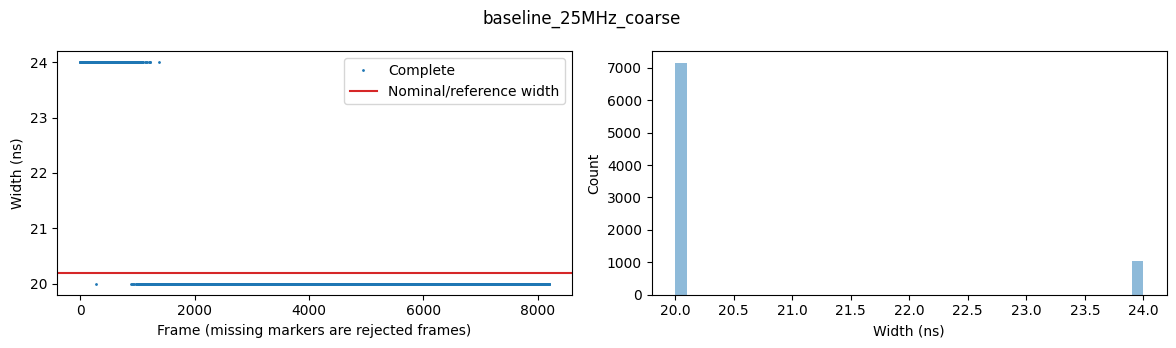

In [9]:
SIGNAL_IDENTITY, identity_captures = signal_identity_check(
    bench, BASELINE_FREQUENCY_HZ, frames=SWEEP_FRAMES, widths_ns=[12.2,20.2,28.2])
print(json.dumps(SIGNAL_IDENTITY, indent=2))
if not SIGNAL_IDENTITY["passed"]:
    raise RuntimeError("Resolve source identity before calibration: "+str(SIGNAL_IDENTITY["errors"]))
baseline = take("baseline_25MHz_coarse", BASELINE_FREQUENCY_HZ, BASELINE_WIDTH_NS, frames=FRAME_COUNT)
quality_guard(baseline)
show_and_save(plot_capture(baseline), "baseline_25MHz.png")


## 3. Fresh code-density calibration

Use several common periods near1 MHz for comparison with earlier images. Both
instruments change rates together. Sampling-clock phase coverage remains an
assumption checked by the existing density/CDF/validity gates. No old LUT or
missing-code exception is inherited. Qualification failure stops the run.


density_r00_f997003: source-start attempt 1/50
  0/8192 complete; saved; restarting sources
density_r00_f997003: source-start attempt 2/50
  8192/8192 complete; accepted
Requested common rate 997003 Hz; applied AWG/frame 996015.936 Hz / 1004 ns
Readbacks: AWG period 1004.1 ns, FPGA period 1004 ns; AWG HIGH 502 ns (requested 502)
density_r00_f997003: 8192/8192 complete (100.0%); operating target 100% after alignment; phase lock unverified; RISE/FALL {'RISE': {'valid_fraction': 1.0, 'status_counts': {'0x01': 7649, '0x21': 543}}, 'FALL': {'valid_fraction': 1.0, 'status_counts': {'0x01': 7608, '0x21': 584}}}; FPGA-fine calibrated 0
Selected source start 2/50; complete fraction across all starts: 50.0%; ledger: C:\Users\kairan\RedPitaya_local_data\RedPitaya_app\scpi-tests\tdc_rigol_results\20261026T150410_720673Z\0125_density_r00_f997003_retries.json
Sparse edge pairs: 128 / 128 ; RISE/FALL drift span (ns): 40.0 40.0
density_r00_f991027: source-start attempt 1/50
  0/8192 complete; saved; r

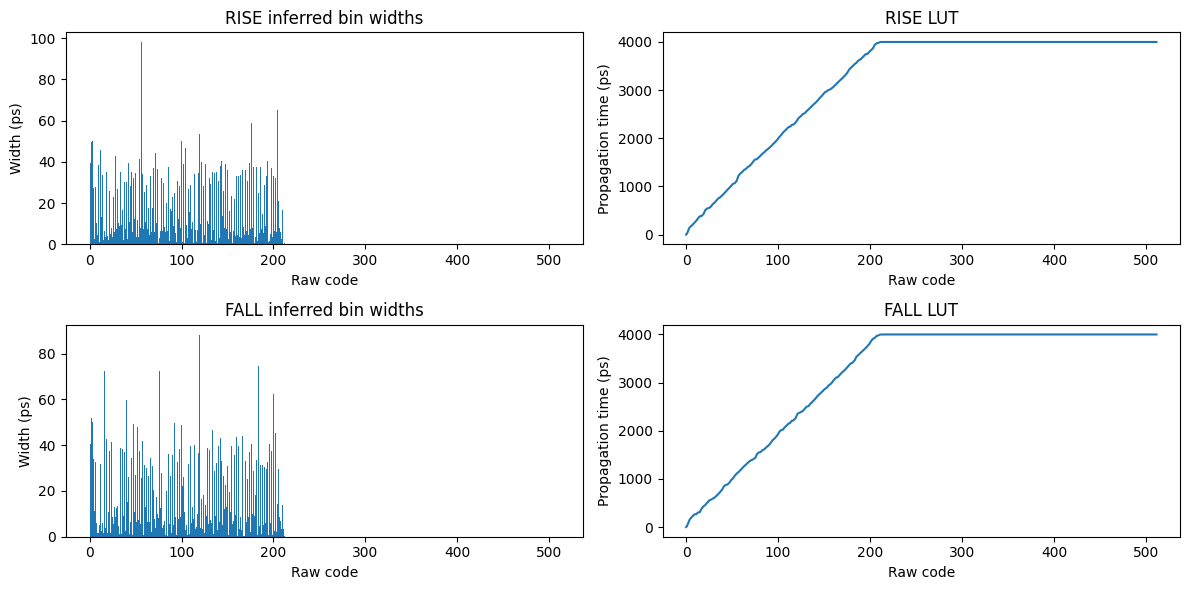

Fresh RISE/FALL tables read back exactly; correction activated.


In [10]:
calibration_captures = []
for round_index in range(CAL_ROUNDS):
    for frequency in CAL_FREQUENCIES_HZ:
        period = plan_matched_period(frequency, MINIMUM_PERIOD_NS)["common_period_ns"]
        calibration_captures.append(take(f"density_r{round_index:02d}_f{frequency:g}",
                                   frequency, period/2, frames=FRAME_COUNT))
candidate = build_candidate(calibration_captures, MIN_EDGE_SAMPLES, MIN_POPULATED_BINS,
                            KNOWN_DEAD_ZONES, provisional_missing_code_ranges=PROVISIONAL_MISSING_CODE_RANGES)
save_json(RUN_DIR/"candidate_luts.json", candidate)
print(json.dumps(candidate["quality"], indent=2))
show_and_save(plot_candidate(candidate), "code_density_and_luts.png")
bench.upload(candidate)
print("Fresh RISE/FALL tables read back exactly; correction activated.")


## 4. Fresh25 MHz precision and chronological drift

Every HIGH width has both coarse and fine captures across repeated source starts.
Keep full distributions and all rejection/retry counts. Per-edge phase is relative
to the first valid sparse pair, not a calibrated launch-to-pin measurement.
No host offset is fitted across these short pulses or applied to raw results.


repeat0_25MHz_w12.2_coarse: source-start attempt 1/50
  0/8192 complete; saved; restarting sources
repeat0_25MHz_w12.2_coarse: source-start attempt 2/50
  0/8192 complete; saved; restarting sources
repeat0_25MHz_w12.2_coarse: source-start attempt 3/50
  8192/8192 complete; accepted
Requested common rate 2.5e+07 Hz; applied AWG/frame 25000000 Hz / 40 ns
Readbacks: AWG period 40 ns, FPGA period 40 ns; AWG HIGH 12.2 ns (requested 12.2)
repeat0_25MHz_w12.2_coarse: 8192/8192 complete (100.0%); operating target 100% after alignment; phase lock unverified; RISE/FALL {'RISE': {'valid_fraction': 1.0, 'status_counts': {'0x01': 7834, '0x21': 358}}, 'FALL': {'valid_fraction': 1.0, 'status_counts': {'0x01': 7675, '0x21': 517}}}; FPGA-fine calibrated 0
Selected source start 3/50; complete fraction across all starts: 33.3%; ledger: C:\Users\kairan\RedPitaya_local_data\RedPitaya_app\scpi-tests\tdc_rigol_results\20261026T150410_720673Z\0184_repeat0_25MHz_w12.2_coarse_retries.json
Sparse edge pairs: 128

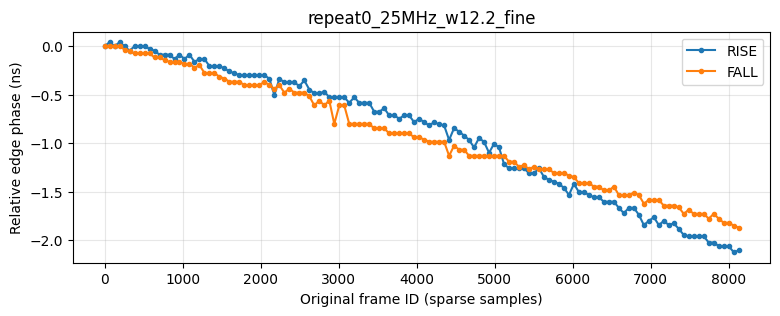

repeat0_25MHz_w20.2_coarse: source-start attempt 1/50
  8192/8192 complete; accepted
Requested common rate 2.5e+07 Hz; applied AWG/frame 25000000 Hz / 40 ns
Readbacks: AWG period 40 ns, FPGA period 40 ns; AWG HIGH 20.2 ns (requested 20.2)
repeat0_25MHz_w20.2_coarse: 8192/8192 complete (100.0%); operating target 100% after alignment; phase lock unverified; RISE/FALL {'RISE': {'valid_fraction': 1.0, 'status_counts': {'0x01': 7721, '0x21': 471}}, 'FALL': {'valid_fraction': 1.0, 'status_counts': {'0x01': 7497, '0x21': 695}}}; FPGA-fine calibrated 0
Selected source start 1/50; complete fraction across all starts: 100.0%; ledger: C:\Users\kairan\RedPitaya_local_data\RedPitaya_app\scpi-tests\tdc_rigol_results\20261026T150410_720673Z\0189_repeat0_25MHz_w20.2_coarse_retries.json
Sparse edge pairs: 128 / 128 ; RISE/FALL drift span (ns): 0.0 4.0
repeat0_25MHz_w20.2_fine: source-start attempt 1/50
  0/8192 complete; saved; restarting sources
repeat0_25MHz_w20.2_fine: source-start attempt 2/50
  81

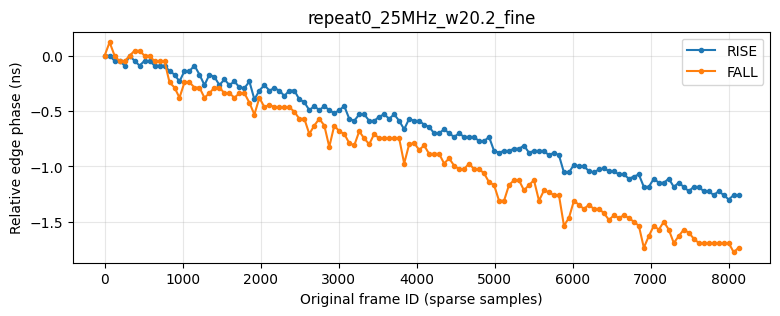

repeat0_25MHz_w28.2_coarse: source-start attempt 1/50
  0/8192 complete; saved; restarting sources
repeat0_25MHz_w28.2_coarse: source-start attempt 2/50
  0/8192 complete; saved; restarting sources
repeat0_25MHz_w28.2_coarse: source-start attempt 3/50
  8192/8192 complete; accepted
Requested common rate 2.5e+07 Hz; applied AWG/frame 25000000 Hz / 40 ns
Readbacks: AWG period 40 ns, FPGA period 40 ns; AWG HIGH 28.2 ns (requested 28.2)
repeat0_25MHz_w28.2_coarse: 8192/8192 complete (100.0%); operating target 100% after alignment; phase lock unverified; RISE/FALL {'RISE': {'valid_fraction': 1.0, 'status_counts': {'0x01': 7626, '0x21': 566}}, 'FALL': {'valid_fraction': 1.0, 'status_counts': {'0x01': 7738, '0x21': 454}}}; FPGA-fine calibrated 0
Selected source start 3/50; complete fraction across all starts: 33.3%; ledger: C:\Users\kairan\RedPitaya_local_data\RedPitaya_app\scpi-tests\tdc_rigol_results\20261026T150410_720673Z\0192_repeat0_25MHz_w28.2_coarse_retries.json
Sparse edge pairs: 128

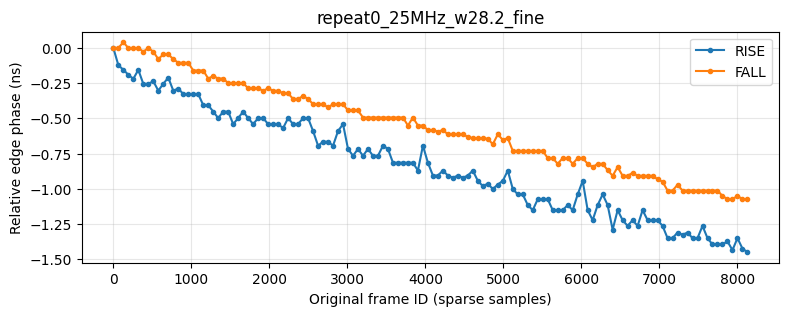

repeat1_25MHz_w12.2_coarse: source-start attempt 1/50
  8192/8192 complete; accepted
Requested common rate 2.5e+07 Hz; applied AWG/frame 25000000 Hz / 40 ns
Readbacks: AWG period 40 ns, FPGA period 40 ns; AWG HIGH 12.2 ns (requested 12.2)
repeat1_25MHz_w12.2_coarse: 8192/8192 complete (100.0%); operating target 100% after alignment; phase lock unverified; RISE/FALL {'RISE': {'valid_fraction': 1.0, 'status_counts': {'0x01': 7587, '0x21': 605}}, 'FALL': {'valid_fraction': 1.0, 'status_counts': {'0x01': 7485, '0x21': 707}}}; FPGA-fine calibrated 0
Selected source start 1/50; complete fraction across all starts: 100.0%; ledger: C:\Users\kairan\RedPitaya_local_data\RedPitaya_app\scpi-tests\tdc_rigol_results\20261026T150410_720673Z\0198_repeat1_25MHz_w12.2_coarse_retries.json
Sparse edge pairs: 128 / 128 ; RISE/FALL drift span (ns): 4.0 0.0
repeat1_25MHz_w12.2_fine: source-start attempt 1/50
  8192/8192 complete; accepted
Requested common rate 2.5e+07 Hz; applied AWG/frame 25000000 Hz / 40 n

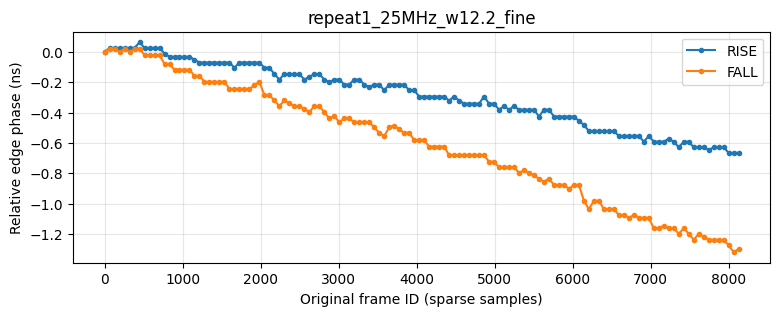

repeat1_25MHz_w20.2_coarse: source-start attempt 1/50
  0/8192 complete; saved; restarting sources
repeat1_25MHz_w20.2_coarse: source-start attempt 2/50
  5897/8192 complete; saved; restarting sources
repeat1_25MHz_w20.2_coarse: source-start attempt 3/50
  8192/8192 complete; accepted
Requested common rate 2.5e+07 Hz; applied AWG/frame 25000000 Hz / 40 ns
Readbacks: AWG period 40 ns, FPGA period 40 ns; AWG HIGH 20.2 ns (requested 20.2)
repeat1_25MHz_w20.2_coarse: 8192/8192 complete (100.0%); operating target 100% after alignment; phase lock unverified; RISE/FALL {'RISE': {'valid_fraction': 1.0, 'status_counts': {'0x01': 7504, '0x21': 688}}, 'FALL': {'valid_fraction': 1.0, 'status_counts': {'0x01': 7642, '0x21': 550}}}; FPGA-fine calibrated 0
Selected source start 3/50; complete fraction across all starts: 57.3%; ledger: C:\Users\kairan\RedPitaya_local_data\RedPitaya_app\scpi-tests\tdc_rigol_results\20261026T150410_720673Z\0200_repeat1_25MHz_w20.2_coarse_retries.json
Sparse edge pairs: 

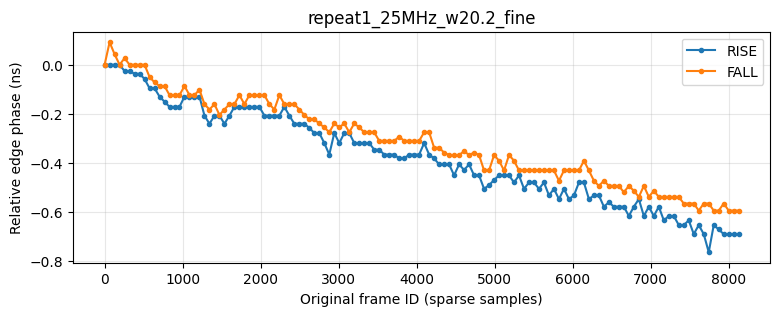

repeat1_25MHz_w28.2_coarse: source-start attempt 1/50
  0/8192 complete; saved; restarting sources
repeat1_25MHz_w28.2_coarse: source-start attempt 2/50
  8192/8192 complete; accepted
Requested common rate 2.5e+07 Hz; applied AWG/frame 25000000 Hz / 40 ns
Readbacks: AWG period 40 ns, FPGA period 40 ns; AWG HIGH 28.2 ns (requested 28.2)
repeat1_25MHz_w28.2_coarse: 8192/8192 complete (100.0%); operating target 100% after alignment; phase lock unverified; RISE/FALL {'RISE': {'valid_fraction': 1.0, 'status_counts': {'0x01': 7648, '0x21': 544}}, 'FALL': {'valid_fraction': 1.0, 'status_counts': {'0x01': 7249, '0x21': 943}}}; FPGA-fine calibrated 0
Selected source start 2/50; complete fraction across all starts: 50.0%; ledger: C:\Users\kairan\RedPitaya_local_data\RedPitaya_app\scpi-tests\tdc_rigol_results\20261026T150410_720673Z\0204_repeat1_25MHz_w28.2_coarse_retries.json
Sparse edge pairs: 128 / 128 ; RISE/FALL drift span (ns): 4.0 0.0
repeat1_25MHz_w28.2_fine: source-start attempt 1/50
  0

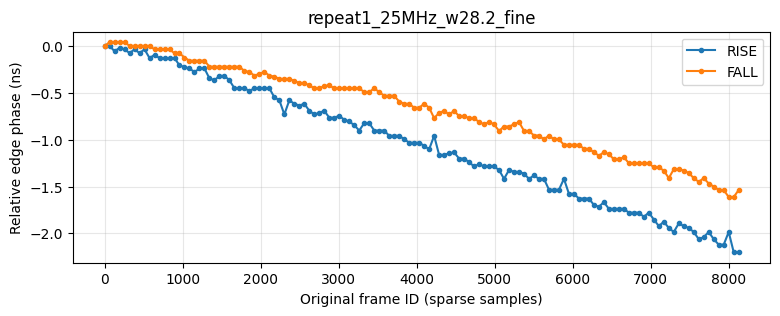

repeat2_25MHz_w12.2_coarse: source-start attempt 1/50
  0/8192 complete; saved; restarting sources
repeat2_25MHz_w12.2_coarse: source-start attempt 2/50
  0/8192 complete; saved; restarting sources
repeat2_25MHz_w12.2_coarse: source-start attempt 3/50
  0/8192 complete; saved; restarting sources
repeat2_25MHz_w12.2_coarse: source-start attempt 4/50
  8192/8192 complete; accepted
Requested common rate 2.5e+07 Hz; applied AWG/frame 25000000 Hz / 40 ns
Readbacks: AWG period 40 ns, FPGA period 40 ns; AWG HIGH 12.2 ns (requested 12.2)
repeat2_25MHz_w12.2_coarse: 8192/8192 complete (100.0%); operating target 100% after alignment; phase lock unverified; RISE/FALL {'RISE': {'valid_fraction': 1.0, 'status_counts': {'0x01': 7613, '0x21': 579}}, 'FALL': {'valid_fraction': 1.0, 'status_counts': {'0x01': 7806, '0x21': 386}}}; FPGA-fine calibrated 0
Selected source start 4/50; complete fraction across all starts: 25.0%; ledger: C:\Users\kairan\RedPitaya_local_data\RedPitaya_app\scpi-tests\tdc_rigol_

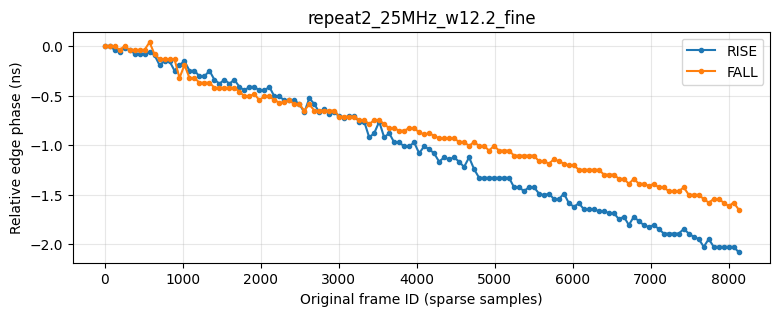

repeat2_25MHz_w20.2_coarse: source-start attempt 1/50
  0/8192 complete; saved; restarting sources
repeat2_25MHz_w20.2_coarse: source-start attempt 2/50
  8192/8192 complete; accepted
Requested common rate 2.5e+07 Hz; applied AWG/frame 25000000 Hz / 40 ns
Readbacks: AWG period 40 ns, FPGA period 40 ns; AWG HIGH 20.2 ns (requested 20.2)
repeat2_25MHz_w20.2_coarse: 8192/8192 complete (100.0%); operating target 100% after alignment; phase lock unverified; RISE/FALL {'RISE': {'valid_fraction': 1.0, 'status_counts': {'0x01': 7742, '0x21': 450}}, 'FALL': {'valid_fraction': 1.0, 'status_counts': {'0x01': 7543, '0x21': 649}}}; FPGA-fine calibrated 0
Selected source start 2/50; complete fraction across all starts: 50.0%; ledger: C:\Users\kairan\RedPitaya_local_data\RedPitaya_app\scpi-tests\tdc_rigol_results\20261026T150410_720673Z\0214_repeat2_25MHz_w20.2_coarse_retries.json
Sparse edge pairs: 128 / 128 ; RISE/FALL drift span (ns): 0.0 4.0
repeat2_25MHz_w20.2_fine: source-start attempt 1/50
  8

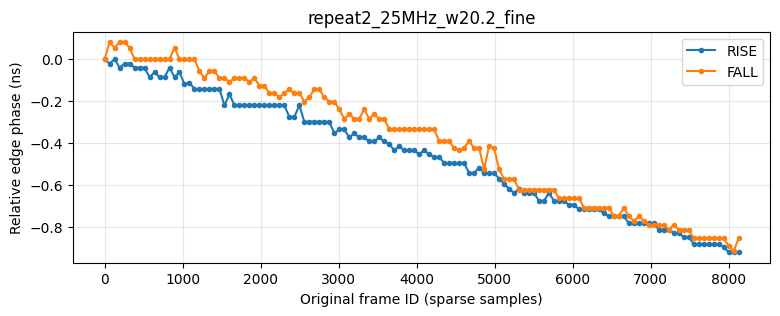

repeat2_25MHz_w28.2_coarse: source-start attempt 1/50
  5060/8192 complete; saved; restarting sources
repeat2_25MHz_w28.2_coarse: source-start attempt 2/50
  0/8192 complete; saved; restarting sources
repeat2_25MHz_w28.2_coarse: source-start attempt 3/50
  8192/8192 complete; accepted
Requested common rate 2.5e+07 Hz; applied AWG/frame 25000000 Hz / 40 ns
Readbacks: AWG period 40 ns, FPGA period 40 ns; AWG HIGH 28.2 ns (requested 28.2)
repeat2_25MHz_w28.2_coarse: 8192/8192 complete (100.0%); operating target 100% after alignment; phase lock unverified; RISE/FALL {'RISE': {'valid_fraction': 1.0, 'status_counts': {'0x01': 7532, '0x21': 660}}, 'FALL': {'valid_fraction': 1.0, 'status_counts': {'0x01': 7756, '0x21': 436}}}; FPGA-fine calibrated 0
Selected source start 3/50; complete fraction across all starts: 53.9%; ledger: C:\Users\kairan\RedPitaya_local_data\RedPitaya_app\scpi-tests\tdc_rigol_results\20261026T150410_720673Z\0217_repeat2_25MHz_w28.2_coarse_retries.json
Sparse edge pairs: 

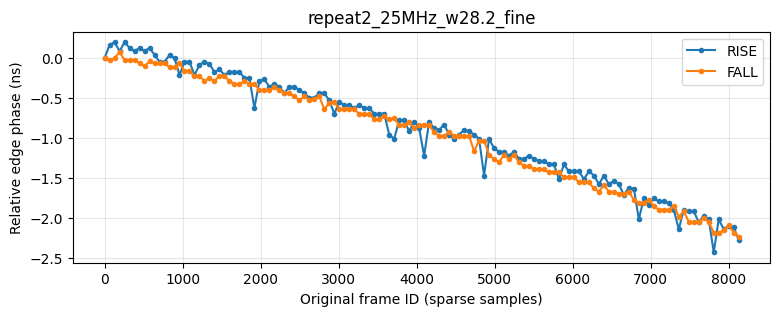

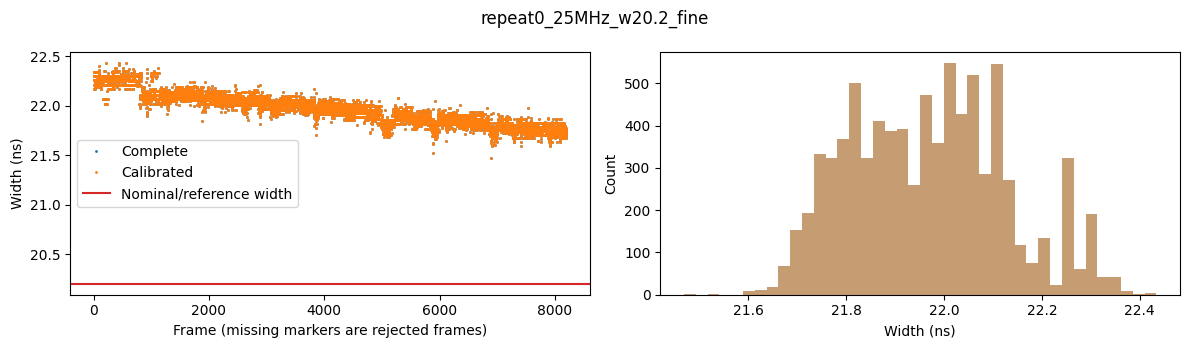

In [11]:
validation_pairs, precision_results, drift_captures = [], [], []
for repeat in range(DRIFT_REPEATS):
    for width in [12.2,20.2,28.2]:
        coarse = take(f"repeat{repeat}_25MHz_w{width:g}_coarse",25e6,width,frames=FRAME_COUNT)
        fine = take(f"repeat{repeat}_25MHz_w{width:g}_fine",25e6,width,fine=True,frames=FRAME_COUNT)
        comparison = precision_comparison(coarse,fine)
        comparison.update(repeat=repeat,requested_width_ns=width)
        precision_results.append(comparison);validation_pairs.append((coarse,fine));drift_captures.append(fine)
        print(json.dumps(comparison,indent=2))
        d=fine["edge_diagnostics"]
        if d["valid_pairs"]:
            fig,ax=plt.subplots(figsize=(9,3))
            ax.plot(d["frame_ids"],d["rise_phase_ns"],".-",label="RISE")
            ax.plot(d["frame_ids"],d["fall_phase_ns"],".-",label="FALL")
            ax.set(xlabel="Original frame ID (sparse samples)",ylabel="Relative edge phase (ns)",title=fine["label"])
            ax.legend();ax.grid(alpha=.3)
            show_and_save(fig,fine["label"]+"_edge_drift.png")
save_json(RUN_DIR/"fresh_25MHz_precision.json",precision_results)
show_and_save(plot_capture(validation_pairs[1][1]),"fresh_25MHz_fine.png")


## 5. Rate transfer, duty coverage and full capacity

Use30/50/70% duty initially so the narrowest nominal HIGH/LOW at25 MHz is12 ns.
Report actual common rates after4 ns snapping, fine validity, full width SD/bias,
all retries and edge drift. A selected complete burst is not unconditional
capture efficiency or proof of clock lock. Tests above25 MHz are rejected by the
hardware minimum; never pair a faster source with slower acquisition frames.


rate_f1e+06_d30: source-start attempt 1/50
  4096/4096 complete; accepted
Requested common rate 1e+06 Hz; applied AWG/frame 1000000 Hz / 1000 ns
Readbacks: AWG period 1000 ns, FPGA period 1000 ns; AWG HIGH 300 ns (requested 300)
rate_f1e+06_d30: 4096/4096 complete (100.0%); operating target 100% after alignment; phase lock unverified; RISE/FALL {'RISE': {'valid_fraction': 1.0, 'status_counts': {'0x01': 3827, '0x21': 269}}, 'FALL': {'valid_fraction': 1.0, 'status_counts': {'0x01': 3810, '0x21': 286}}}; FPGA-fine calibrated 4096
Selected source start 1/50; complete fraction across all starts: 100.0%; ledger: C:\Users\kairan\RedPitaya_local_data\RedPitaya_app\scpi-tests\tdc_rigol_results\20261026T150410_720673Z\0221_rate_f1e+06_d30_retries.json
Sparse edge pairs: 64 / 64 ; RISE/FALL drift span (ns): 19.64 20.07
rate_f1e+06_d50: source-start attempt 1/50
  4096/4096 complete; accepted
Requested common rate 1e+06 Hz; applied AWG/frame 1000000 Hz / 1000 ns
Readbacks: AWG period 1000 ns, FPGA

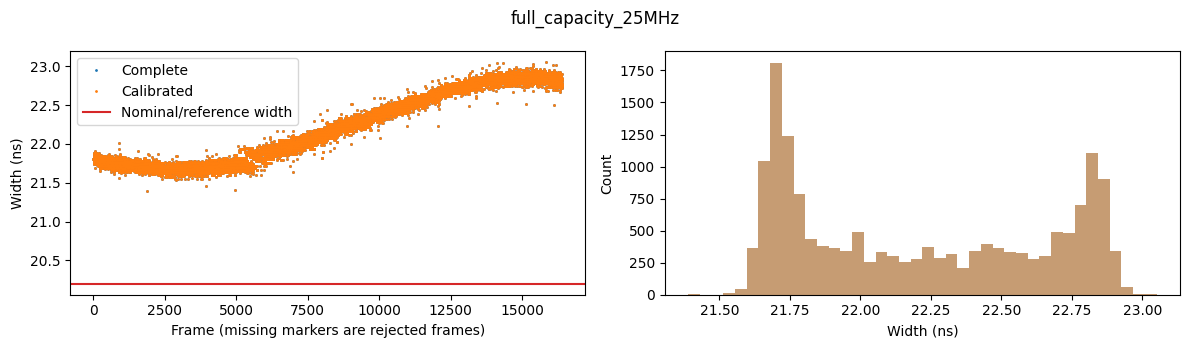

Unsupported common rate: Common period 40 ns is below the current FPGA minimum 40 ns. No mismatched overspeed frames are allowed.
Unsupported common rate: Common period 20 ns is below the current FPGA minimum 40 ns. No mismatched overspeed frames are allowed.


In [12]:
rate_captures=[]
for frequency in [1e6,5e6,10e6,15e6,20e6,25e6]:
    period=plan_matched_period(frequency,MINIMUM_PERIOD_NS)["common_period_ns"]
    for duty in [30.,50.,70.]:
        rate_captures.append(take(f"rate_f{frequency:g}_d{duty:g}",frequency,
                                  period*duty/100,fine=True))
save_json(RUN_DIR/"rate_duty_summary.json",[dict(label=c["label"],timing=c["timing"],summary=c["summary"],
         edge_diagnostics=c["edge_diagnostics"]) for c in rate_captures])
full_capacity=take("full_capacity_25MHz",25e6,20.2,fine=True,frames=PREFLIGHT["image"]["capacity"])
show_and_save(plot_capture(full_capacity),"full_capacity_25MHz.png")
for frequency in [25_000_001.,50e6]:
    try: plan_matched_period(frequency,MINIMUM_PERIOD_NS)
    except ValueError as exc: print("Unsupported common rate:",exc)
    else: raise RuntimeError("Overspeed planner guard failed")


In [13]:
report=dict(image=PREFLIGHT["image"],timing_policy="matched_period_v1",target_hz=25e6,
            phase_lock_verified=False,alignment_survey=ALIGNMENT_SURVEY,
            candidate_quality=candidate["quality"],calibration_limitations=candidate["limitations"],
            fresh_precision=precision_results,full_capacity_summary=full_capacity["summary"],
            full_capacity_edge_diagnostics=full_capacity["edge_diagnostics"],
            results_conditioned_on_complete_bursts=PHASE_RETRIES,
            retry_ledgers=[str(p) for p in sorted(RUN_DIR.glob("*_retries.json"))],
            timing_closed=IMPLEMENTATION_WNS_NS is not None and IMPLEMENTATION_WNS_NS>=0,
            note="Finite bursts only; no demonstrated absolute accuracy or physical precision improvement.")
save_json(RUN_DIR/"run_report.json",report)
print("Report:",RUN_DIR/"run_report.json")
print(bench.stop())


Report: C:\Users\kairan\RedPitaya_local_data\RedPitaya_app\scpi-tests\tdc_rigol_results\20261026T150410_720673Z\run_report.json
AWG selected output OFF; FPGA pulse output OFF; width capture idle.


## STOP / recover

Every acquisition attempts cleanup in finally, including on interruption.
The next cell reconnects independently and turns both outputs OFF/aborts capture.
Calling bench.stop() alone does not erase LUTs or require fresh calibration.

A bitstream reload resets input selection and runtime calibration state; STOP
does not restore them. If you reloaded the exact same bitstream with the same
measurement setup, retain the qualified candidate and restore it explicitly:

```python
bench.preflight()       # Recheck interface and restore SINGLE input selection.
bench.upload(candidate) # Write both saved LUTs, verify exact readback, activate.
```

If the kernel was restarted, load candidate from the original run's
candidate_luts.json first. VERSION18 alone does not establish identical routing.
A new implementation/input path or uncertain build identity needs fresh
calibration. Restoring old LUTs does not cure the saved width bias/drift.
After a server restart, recheck input/calibration state before fine captures.
Coarse-only diagnostics do not need fine LUT calibration.


In [14]:
print(bench.stop())


AWG selected output OFF; FPGA pulse output OFF; width capture idle.


In [15]:
# Same-image LUT recovery is documented in STOP / recover below.
